In [5]:
!pip install -q ultralytics==8.4.216 "numpy>=2.0" kagglehub

100%|██████████| 191M/191M [00:02<00:00, 70.2MB/s]

Extracting files...


Классы: ['BIODEGRADABLE', 'CARDBOARD', 'GLASS', 'METAL', 'PAPER', 'PLASTIC']
TRAIN: 800 картинок, 5491 объектов (пустых: 0)
VALID: 150 картинок, 1382 объектов (пустых: 0)
TEST: 150 картинок, 487 объектов (пустых: 0)


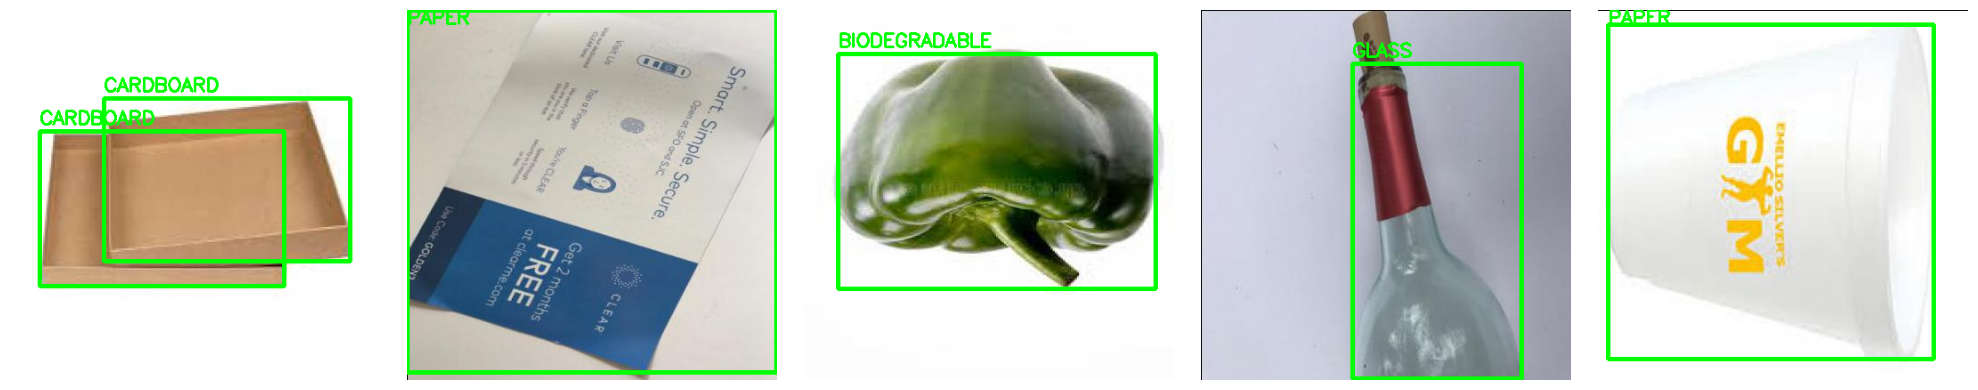

In [2]:
import shutil, random, yaml, cv2, kagglehub
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Скачиваем датасет прямо в Colab (без ключей и паролей)
raw_path = Path(kagglehub.dataset_download("viswaprakash1990/garbage-detection"))
yaml_files = list(raw_path.rglob("data.yaml"))
src_base = yaml_files[0].parent if yaml_files else raw_path

with open(src_base / "data.yaml") as f:
    src_cfg = yaml.safe_load(f)
class_names = src_cfg["names"]
print("Классы:", class_names)

# 2. Собираем компактный честный датасет (800 train / 150 valid / 150 test, seed=42)
dst_base = Path("/content/garbage_dataset")
if dst_base.exists():
    shutil.rmtree(dst_base)

limits = {"train": 800, "valid": 150, "test": 150}
random.seed(42)

for split, limit in limits.items():
    src_imgs = sorted((src_base / split / "images").glob("*.*"))
    chosen = random.sample(src_imgs, min(limit, len(src_imgs)))
    (dst_base / split / "images").mkdir(parents=True, exist_ok=True)
    (dst_base / split / "labels").mkdir(parents=True, exist_ok=True)

    for img_p in chosen:
        shutil.copy(img_p, dst_base / split / "images" / img_p.name)
        lbl_p = src_base / split / "labels" / f"{img_p.stem}.txt"
        if lbl_p.exists():
            shutil.copy(lbl_p, dst_base / split / "labels" / lbl_p.name)

# 3. Создаём чистый data.yaml
data_cfg = {
    "path": str(dst_base.resolve()),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "names": class_names
}
with open("/content/data.yaml", "w") as f:
    yaml.dump(data_cfg, f, sort_keys=False)

# 4. Считаем статистику для отчёта и README
for split in ["train", "valid", "test"]:
    imgs = list((dst_base / split / "images").glob("*.*"))
    lbls = list((dst_base / split / "labels").glob("*.txt"))
    total_boxes = sum(len([l for l in p.read_text().splitlines() if l.strip()]) for p in lbls)
    empty_lbls = sum(1 for p in lbls if not p.read_text().strip())
    print(f"{split.upper()}: {len(imgs)} картинок, {total_boxes} объектов (пустых: {empty_lbls})")

# 5. Рисуем 5 случайных картинок с разметкой (Ground Truth)
random.seed(42)
sample_imgs = random.sample(list((dst_base / "train" / "images").glob("*.*")), 5)
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, img_path in zip(axes, sample_imgs):
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape
    lbl_path = dst_base / "train" / "labels" / f"{img_path.stem}.txt"
    if lbl_path.exists():
        for line in lbl_path.read_text().splitlines():
            parts = line.split()
            if len(parts) >= 5:
                cls_id, xc, yc, bw, bh = int(parts[0]), *map(float, parts[1:5])
                x1, y1 = int((xc - bw/2)*w), int((yc - bh/2)*h)
                x2, y2 = int((xc + bw/2)*w), int((yc + bh/2)*h)
                cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)
                cv2.putText(img, str(class_names[cls_id]), (x1, max(y1 - 8, 15)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
    ax.imshow(img)
    ax.axis("off")
plt.tight_layout()
plt.savefig("ground_truth_samples.png", dpi=150)
plt.show()

In [6]:
import os, time
from pathlib import Path
from ultralytics import YOLO

os.environ["WANDB_DISABLED"] = "true"

# --- 1. BASELINE: YOLOv8n ---
print("🚀 Запускаем Baseline: YOLOv8n...")
t0 = time.time()
res_v8 = YOLO("yolov8n.pt").train(
    data="/content/data.yaml",
    epochs=10,
    imgsz=320,
    batch=16,
    seed=42,
    deterministic=True,
    project="/content/runs_battle",
    name="baseline_yolov8n",
    exist_ok=True
)
time_v8 = time.time() - t0
best_v8_path = Path(res_v8.save_dir) / "weights" / "best.pt"
val_v8 = YOLO(str(best_v8_path)).val(data="/content/data.yaml", split="val", imgsz=320)

# --- 2. EXPERIMENT: YOLO11n (меняем ТОЛЬКО архитектуру) ---
print("\n🚀 Запускаем Experiment: YOLO11n...")
t1 = time.time()
res_v11 = YOLO("yolo11n.pt").train(
    data="/content/data.yaml",
    epochs=10,
    imgsz=320,
    batch=16,
    seed=42,
    deterministic=True,
    project="/content/runs_battle",
    name="experiment_yolo11n",
    exist_ok=True
)
time_v11 = time.time() - t1
best_v11_path = Path(res_v11.save_dir) / "weights" / "best.pt"
val_v11 = YOLO(str(best_v11_path)).val(data="/content/data.yaml", split="val", imgsz=320)

# --- 3. ИТОГИ БАТТЛА НА ВАЛИДАЦИИ (VAL) ---
print("\n================ ИТОГИ БАТТЛА (VAL) ================")
print(f"Baseline   (YOLOv8n) | P: {val_v8.box.mp:.4f} | R: {val_v8.box.mr:.4f} | mAP@0.50: {val_v8.box.map50:.4f} | Время: {time_v8/60:.2f} мин")
print(f"Experiment (YOLO11n) | P: {val_v11.box.mp:.4f} | R: {val_v11.box.mr:.4f} | mAP@0.50: {val_v11.box.map50:.4f} | Время: {time_v11/60:.2f} мин")
print("====================================================")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
🚀 Запускаем Baseline: YOLOv8n...
New https://pypi.org/project/ultralytics/8.4.218 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dy

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,266 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 534.2±245.7 MB/s, size: 15.9 KB)
val: Scanning /content/garbage_dataset/test/labels... 150 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 150/150 621.6it/s 0.2s
val: New cache created: /content/garbage_dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 4.0it/s 2.5s
                   all        150        487      0.481      0.314      0.202      0.162
             CARDBOARD          3          5     0.0714        0.2      0.015      0.015
                 METAL         27         64      0.642      0.531       0.36       0.31
                 PAPER         80        202        0.7      0.312       0.28       0.22
               PLASTIC         41        216      0.511      0.213 

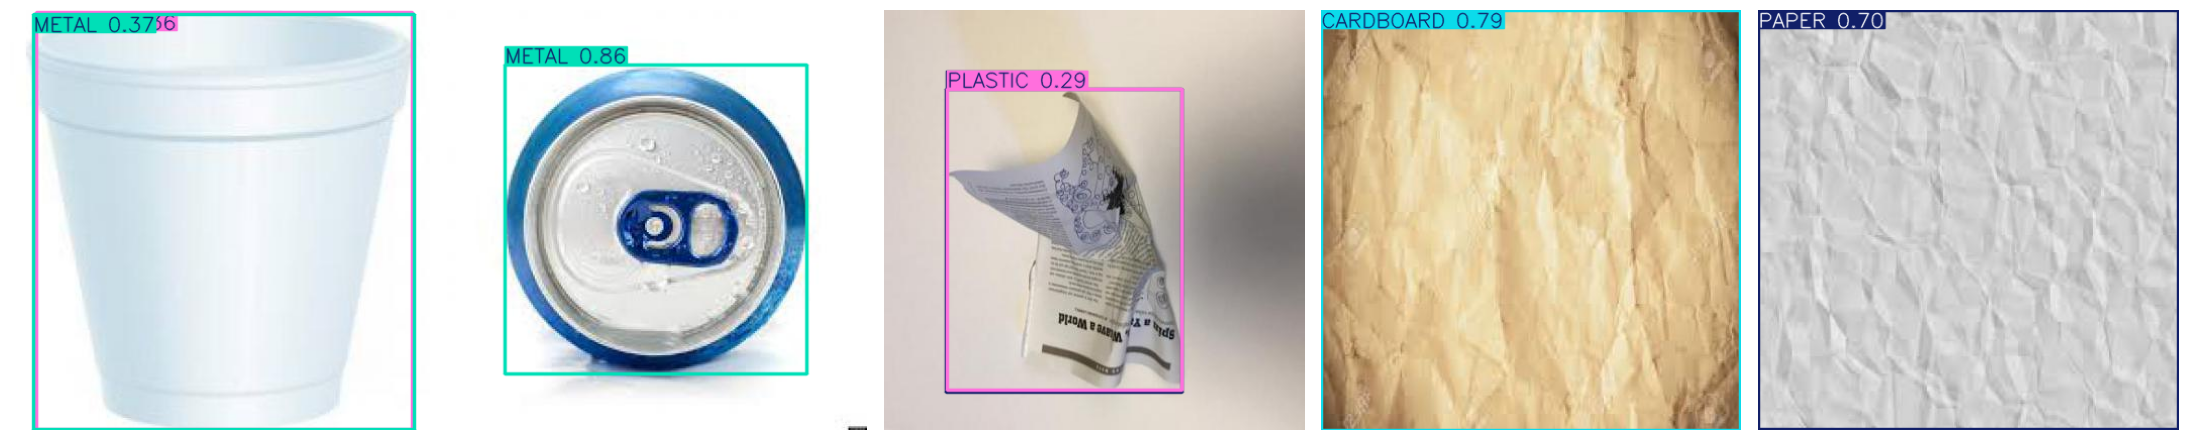

Ошибка #1 (metal100_jpg.rf.8605f3d87c15f6f37575fa2907d5bc6c.jpg): GT (3 шт) = [METAL, METAL, METAL] | Pred (3 шт) = [GLASS, METAL, METAL]
Ошибка #2 (metal1040_jpg.rf.c6e8f2418b51b7d8891f49df3cecf80b.jpg): GT (1 шт) = [METAL] | Pred (1 шт) = [PLASTIC]
Ошибка #3 (metal1165_jpg.rf.b864bfe4c1041d36cb038ee304fb573a.jpg): GT (3 шт) = [METAL, METAL, METAL] | Pred (1 шт) = [METAL]


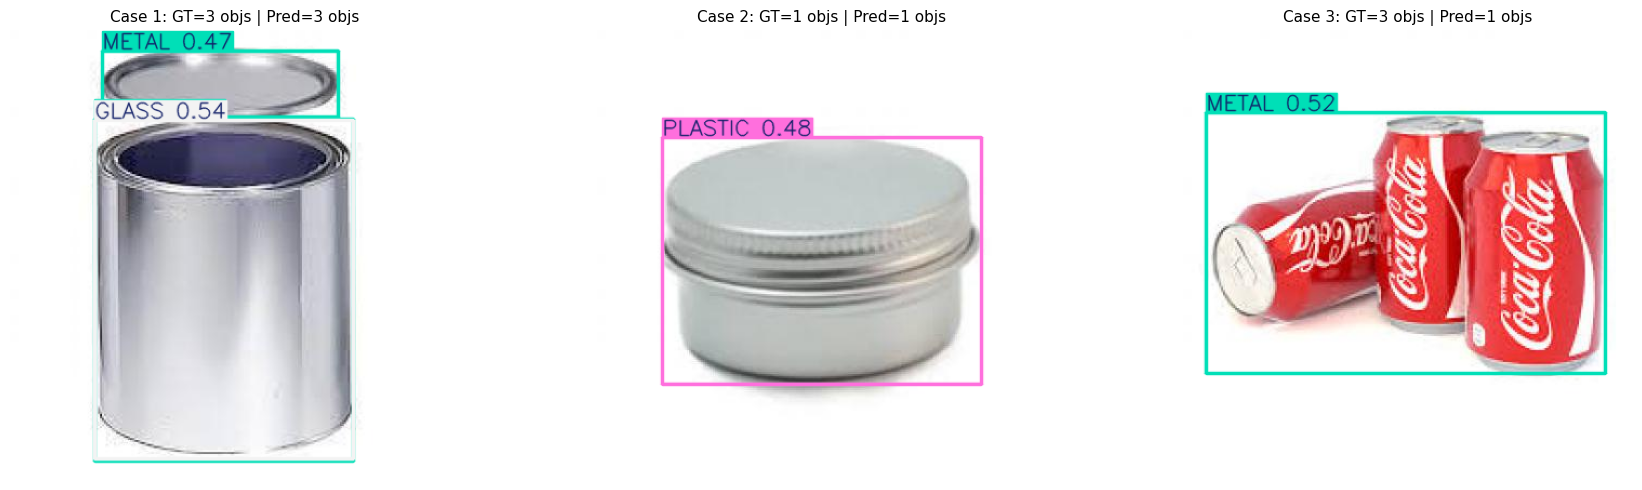


✅ Готово! Архив project_artifacts.zip создан (в левой панели Files).


In [7]:
import random, shutil, cv2, yaml
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO

base_dir = Path("/content/runs_battle/baseline_yolov8n")
exp_dir = Path("/content/runs_battle/experiment_yolo11n")
best_model = YOLO(str(exp_dir / "weights" / "best.pt"))

with open("/content/data.yaml") as f:
    class_names = yaml.safe_load(f)["names"]

# 1. Финальная оценка победителя (YOLO11n) на отложенном TEST
test_metrics = best_model.val(data="/content/data.yaml", split="test", imgsz=320, conf=0.25, iou=0.50)

print("\n=== ФИНАЛЬНЫЕ РЕЗУЛЬТАТЫ YOLO11n НА TEST (conf=0.25, IoU=0.50) ===")
print(f"Precision (P): {test_metrics.box.mp:.4f}")
print(f"Recall (R):    {test_metrics.box.mr:.4f}")
print(f"mAP@0.50:      {test_metrics.box.map50:.4f}")

# 2. Сохраняем 5 тестовых фото с предсказаниями
test_imgs = sorted(list(Path("/content/garbage_dataset/test/images").glob("*.*")))
random.seed(42)
sample_test = random.sample(test_imgs, 5)

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, img_path in zip(axes, sample_test):
    res = best_model.predict(str(img_path), imgsz=320, conf=0.25, iou=0.50, verbose=False)[0]
    ax.imshow(cv2.cvtColor(res.plot(), cv2.COLOR_BGR2RGB))
    ax.axis("off")
plt.tight_layout()
plt.savefig("test_predictions_5.png", dpi=150)
plt.show()

# 3. Находим 3 реальные ошибки на TEST для Failure Analysis
failures = []
for img_path in test_imgs:
    lbl_path = Path("/content/garbage_dataset/test/labels") / f"{img_path.stem}.txt"
    gt_classes = [int(line.split()[0]) for line in lbl_path.read_text().splitlines() if line.strip()]
    res = best_model.predict(str(img_path), imgsz=320, conf=0.25, iou=0.50, verbose=False)[0]
    pred_classes = [int(c) for c in res.boxes.cls.tolist()]

    if sorted(gt_classes) != sorted(pred_classes):
        failures.append((img_path, gt_classes, pred_classes, res))
    if len(failures) == 3:
        break

fig, axes = plt.subplots(1, len(failures), figsize=(18, 5))
if len(failures) == 1:
    axes = [axes]
for idx, (ax, (img_path, gt_c, pr_c, res)) in enumerate(zip(axes, failures), 1):
    gt_str = ", ".join(class_names[c] for c in gt_c[:6]) + ("..." if len(gt_c) > 6 else "")
    pr_str = ", ".join(class_names[c] for c in pr_c[:6]) + ("..." if len(pr_c) > 6 else "")
    print(f"Ошибка #{idx} ({img_path.name}): GT ({len(gt_c)} шт) = [{gt_str}] | Pred ({len(pr_c)} шт) = [{pr_str}]")
    ax.imshow(cv2.cvtColor(res.plot(), cv2.COLOR_BGR2RGB))
    ax.set_title(f"Case {idx}: GT={len(gt_c)} objs | Pred={len(pr_c)} objs", fontsize=11)
    ax.axis("off")
plt.tight_layout()
plt.savefig("failure_cases_3.png", dpi=150)
plt.show()

# 4. Собираем все графики и веса в архив project_artifacts.zip
art = Path("/content/project_artifacts")
art.mkdir(exist_ok=True)
shutil.copy(base_dir / "results.png", art / "baseline_yolov8n_results.png")
shutil.copy(exp_dir / "results.png", art / "experiment_yolo11n_results.png")
shutil.copy(exp_dir / "weights" / "best.pt", art / "best_yolo11n.pt")
for f_name in ["ground_truth_samples.png", "test_predictions_5.png", "failure_cases_3.png"]:
    if Path(f_name).exists():
        shutil.copy(f_name, art / f_name)

shutil.make_archive("/content/project_artifacts", "zip", art)
print("\n✅ Готово! Архив project_artifacts.zip создан (в левой панели Files).")